In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import string
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from transformers import BertForSequenceClassification, BertTokenizer
import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
from transformers import AdamW
import matplotlib.pyplot as plt

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
fn_base = pd.read_csv(r'C:\Users\kimli\Documents\GitHub\PIBIC\corretor\base_fn_cg.csv')
tn_base = pd.read_csv(r'C:\Users\kimli\Documents\GitHub\PIBIC\corretor\base_tn_cg.csv')

In [26]:
fn_base['y_true'] = 1
tn_base['y_true'] = 0

In [27]:
base_final = pd.concat([fn_base, tn_base])

In [28]:
base_final = base_final.reset_index(drop=True)
base_final

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s,y_true
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,12,0,13,1
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,12,13,12,1
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,12,12,12,1
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,12,12,13,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,12,12,12,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
563,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,13,0
564,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,13,0
565,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,12,12,12,0
566,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,12,12,12,0


In [29]:
columns_for_train = [i for i in base_final.columns if i != 'y_true']

In [30]:
# Carregar o arquivo gabarito_atualizado.csv
unique_words_df = pd.read_csv(r'C:\Users\kimli\Documents\GitHub\PIBIC\corretor\Bases\joao\gabarito_atualizado.csv')

# Remover valores NaN na coluna 'palavra'
unique_words_df = unique_words_df.dropna(subset=['palavra'])

In [31]:
# Carregar o modelo BERTimbau pré-treinado e o tokenizer
model_name = 'neuralmind/bert-base-portuguese-cased'
bert_model = BertForSequenceClassification.from_pretrained(model_name, num_labels=2)
tokenizer = BertTokenizer.from_pretrained(model_name)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at neuralmind/bert-base-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [36]:
# Tokenizar os dados de treino
X_train = base_final[columns_for_train].tolist()
y_train = torch.tensor(base_final['y'].values)

# Tokenizar as palavras únicas para teste
X_unique_words_tokens = unique_words_df['palavra'].tolist()
y_true = torch.tensor(unique_words_df['y'].values)

AttributeError: 'DataFrame' object has no attribute 'tolist'

In [ ]:
# Criar DataLoader para o conjunto de treino
train_dataset = TensorDataset(X_train['input_ids'], X_train['attention_mask'], y_train)
train_sampler = RandomSampler(train_dataset)
train_dataloader = DataLoader(train_dataset, sampler=train_sampler, batch_size=16)

# Treinar o modelo BERTimbau
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)
optimizer = AdamW(bert_model.parameters(), lr=2e-5)

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\transformers\optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


In [35]:
for epoch in range(10):  # Ajuste o número de épocas conforme necessário
    bert_model.train()
    total_loss = 0
    total_correct = 0
    total_samples = 0
    print(f'Época {epoch + 1}/10:')
    for batch_idx, batch in enumerate(train_dataloader):
        optimizer.zero_grad()
        input_ids, attention_mask, labels = batch
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)
        outputs = bert_model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        logits = outputs.logits
        preds = torch.argmax(logits, dim=1)
        total_correct += torch.sum(preds == labels).item()
        total_samples += len(labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

        # Log a cada 10 batches
        if (batch_idx + 1) % 10 == 0:
            avg_loss = total_loss / (batch_idx + 1)
            avg_accuracy = total_correct / total_samples
            print(f'    Batch {batch_idx + 1}/{len(train_dataloader)} - Loss: {avg_loss:.4f}, Acurácia: {avg_accuracy:.4f}')

Época 1/10:


ValueError: not enough values to unpack (expected 2, got 1)

In [ ]:
# Avaliar o modelo BERTimbau
bert_model.eval()
with torch.no_grad():
    input_ids = X_unique_words_tokens['input_ids'].to(device)
    attention_mask = X_unique_words_tokens['attention_mask'].to(device)
    outputs = bert_model(input_ids, attention_mask=attention_mask)
    logits = outputs.logits
    y_pred = torch.argmax(logits, dim=1).cpu().numpy()

In [ ]:
# Calcular as métricas
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.8749106504646176
Precision: 0.5181128896377422
Recall: 0.8277254374158816
F1 Score: 0.6373056994818652


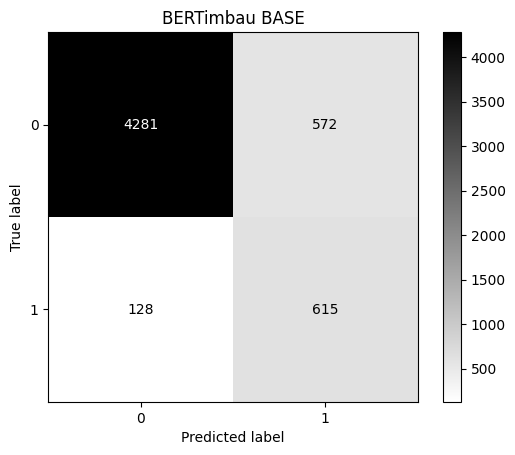

In [ ]:
# Gerar a matriz de confusão
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title('BERTimbau BASE')
plt.show()